# Imports

In [ ]:
import os
import numpy as np
import soundfile as sf
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import librosa
import librosa.display
import torch
import torchaudio
from datasets import load_dataset, Audio
from huggingface_hub import HfFileSystem
from collections import defaultdict
import math
from concurrent.futures import ThreadPoolExecutor, as_completed
import threading

import warnings
warnings.filterwarnings('ignore')

SEED = 1546792
np.random.seed(SEED)

In [ ]:
with open('tokens/token_hf.txt', 'r') as file:
    token = file.read()

In [3]:
from huggingface_hub import login

# Use this to pass the token directly
login(token=token)

# Inspect Structure

In [4]:
dataset = load_dataset(
    "SleepyJesse/ai_music_large",
    streaming=True,
    split="train"
)

sample = next(iter(dataset))

print("=== Column names ===")
print(list(sample.keys()))

print("\n=== Audio field type ===")
print(type(sample['audio']))

# AudioDecoder: call .get_all_samples() to extract array + sample rate
audio_data = sample['audio'].get_all_samples()
audio_array = audio_data.data.numpy().squeeze()  # tensor → numpy, remove channel dim
sr = audio_data.sample_rate

print("\n=== Sample values ===")
print(f"  dtype        : {audio_array.dtype}")
print(f"  shape        : {audio_array.shape}")
print(f"  sampling_rate: {sr}")
print(f"  ai_generated : {sample['ai_generated']}")
print(f"  source       : {sample['source']}")
print(f"  duration (s) : {audio_array.shape[-1] / sr:.2f}")

Resolving data files:   0%|          | 0/147 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/147 [00:00<?, ?it/s]

=== Column names ===
['audio', 'source', 'ai_generated']

=== Audio field type ===
<class 'datasets.features._torchcodec.AudioDecoder'>

=== Sample values ===
  dtype        : float32
  shape        : (2, 87502612)
  sampling_rate: 44100
  ai_generated : False
  source       : https://huggingface.co/datasets/benjamin-paine/free-music-archive-full
  duration (s) : 1984.19


In [6]:
print(f"  duration (s) : {audio_array.shape[-1] / sr / 60:.2f}")

  duration (s) : 33.07


# Data Collection

In [ ]:
# ── Config ──────────────────────────────────────────────
DATASET_NAME  = "SleepyJesse/ai_music_large"
BASE_DIR      = "music_data"
# ────────────────────────────────────────────────────────

os.makedirs(f"{BASE_DIR}/ai",    exist_ok=True)
os.makedirs(f"{BASE_DIR}/human", exist_ok=True)

# ── Step 1: inspect the parquet shards ──────────────────
fs = HfFileSystem()
parquet_files = fs.ls(f"datasets/{DATASET_NAME}/data", detail=False)
parquet_files = sorted([f for f in parquet_files if f.endswith(".parquet")])

print(f"Found {len(parquet_files)} parquet shards:")
for f in parquet_files:
    print(" ", f)

Found 147 parquet shards:
  datasets/SleepyJesse/ai_music_large/data/train-00000-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00001-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00002-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00003-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00004-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00005-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00006-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00007-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00008-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00009-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00010-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00011-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/data/train-00012-of-00147.parquet
  datasets/SleepyJesse/ai_music_large/

Dataset contains 147 parquet shards

In [ ]:
fs = HfFileSystem()
HF_BASE = "datasets/SleepyJesse/ai_music_large/data"

def peek_shard_labels(shard_index):
    path = f"{HF_BASE}/train-{shard_index:05d}-of-00147.parquet"
    with fs.open(path, "rb") as f:
        # Read only the lightweight columns — no audio bytes
        df = pd.read_parquet(f, columns=["ai_generated", "source"])
    return df["ai_generated"].value_counts().to_dict(), df["source"].unique().tolist(), len(df)

for idx in [72, 73, 74, 75, 80, 100, 146]:
    labels, sources, count = peek_shard_labels(idx)
    print(f"Shard {idx:3d}: {count} rows | ai_generated={labels} | sources={sources}")

Shard  72: 136 rows | ai_generated={False: 136} | sources=['https://huggingface.co/datasets/benjamin-paine/free-music-archive-full']
Shard  73: 136 rows | ai_generated={True: 72, False: 64} | sources=['https://huggingface.co/datasets/benjamin-paine/free-music-archive-full', 'https://www.kaggle.com/datasets/miguelcivit/sunocaps']
Shard  74: 136 rows | ai_generated={True: 136} | sources=['https://www.kaggle.com/datasets/miguelcivit/sunocaps']
Shard  75: 136 rows | ai_generated={True: 136} | sources=['https://www.kaggle.com/datasets/miguelcivit/sunocaps', 'https://huggingface.co/datasets/ManzhenWei/MusicSet']
Shard  80: 136 rows | ai_generated={True: 136} | sources=['https://huggingface.co/datasets/ManzhenWei/MusicSet']
Shard 100: 136 rows | ai_generated={True: 136} | sources=['https://huggingface.co/datasets/ManzhenWei/MusicSet']
Shard 146: 136 rows | ai_generated={True: 136} | sources=['https://huggingface.co/datasets/blanchon/udio_dataset']


The first 73 shard are human generated musics, 74th one is the mixed shard and the rest are AI generated musics.

Instead of downloading the entire training dataset of approximately 20,000 music tracks, I am using a subset consisting of 3,000 tracks (1,500 AI-generated and 1,500 human-produced). Since each track will be split into 10-second chunks—a common practice in audio deep learning tasks—the effective number of training samples will increase substantially. To reduce computational time and storage requirements, the models will initially be trained on this subset. If the results are not satisfactory, the dataset can later be expanded by incorporating additional tracks.


In [ ]:
# ── Config ───────────────────────────────────────────────────────────────
DATASET_NAME      = "SleepyJesse/ai_music_large"
TARGET_PER_CLASS  = 1500          
SAMPLE_RATE       = 22050         # half of 44100, still covers full audible range
BASE_DIR          = "music_data"
META_PATH         = f"{BASE_DIR}/metadata.csv"
HF_BASE           = f"hf://datasets/{DATASET_NAME}/data"
BOUNDARY_SHARD    = 73            # mixed shard — skipped for label cleanliness
N_SHARDS          = 147
MAX_WORKERS       = 4
# ─────────────────────────────────────────────────────────────────────────

os.makedirs(f"{BASE_DIR}/ai",    exist_ok=True)
os.makedirs(f"{BASE_DIR}/human", exist_ok=True)

# ── Build shard lists (skip boundary shard 73) ───────────────────────────
human_shards = [f"{HF_BASE}/train-{i:05d}-of-00147.parquet"
                for i in range(0, BOUNDARY_SHARD)]               # shards 0–72

ai_shards    = [f"{HF_BASE}/train-{i:05d}-of-00147.parquet"
                for i in range(BOUNDARY_SHARD + 1, N_SHARDS)]    # shards 74–146

# How many shards do we need? ceil(TARGET / 136)
shards_needed = math.ceil(TARGET_PER_CLASS / 136)
human_shards  = human_shards[:shards_needed]
ai_shards     = ai_shards[:shards_needed]

print(f"Using {len(human_shards)} human shards + {len(ai_shards)} AI shards")
print(f"Expected tracks: ~{len(human_shards)*136} human, ~{len(ai_shards)*136} AI")

# ── Metadata accumulator (thread-safe) ───────────────────────────────────
meta_rows = []
meta_lock = threading.Lock()

# ── Core save function ────────────────────────────────────────────────────
def process_and_save(example, label_str, track_id):
    audio       = example["audio"]
    audio_array = audio["array"]
    sr          = audio["sampling_rate"]
    source      = example.get("source", "unknown")

    # Fix channel layout if needed
    if audio_array.ndim > 1 and audio_array.shape[0] < audio_array.shape[1]:
        audio_array = audio_array.T

    # Convert to mono if stereo
    if audio_array.ndim > 1:
        audio_array = audio_array.mean(axis=1)

    filename  = f"track_{track_id:05d}.wav"
    file_path = os.path.join(BASE_DIR, label_str, filename)
    sf.write(file_path, audio_array, sr, subtype='FLOAT')

    duration_sec = len(audio_array) / sr

    with meta_lock:
        meta_rows.append({
            "filename":     filename,
            "label":        label_str,
            "ai_generated": label_str == "ai",
            "source":       source,
            "sample_rate":  sr,
            "duration_sec": round(duration_sec, 2),
            "n_samples":    len(audio_array),
            "file_path":    file_path,
        })

# ── Stream downloader for one class ──────────────────────────────────────
def download_class(shard_list, label_str, target_count):
    print(f"\n▶ Starting [{label_str}] — {len(shard_list)} shards, target {target_count} tracks")

    ds = load_dataset(
        "parquet",
        data_files={"train": shard_list},
        split="train",
        streaming=True,
    )
    ds = ds.cast_column("audio", Audio(sampling_rate=SAMPLE_RATE))

    count = 0
    for example in ds:
        if count >= target_count:
            break
        process_and_save(example, label_str, count)
        count += 1
        if count % 100 == 0:
            print(f"  [{label_str}] {count}/{target_count} ✓")

    print(f"  [{label_str}] ✅ Done — {count} tracks saved")

# ── Parallel download (human + AI simultaneously) ─────────────────────────
print("=" * 55)
print(f"Downloading {TARGET_PER_CLASS} tracks per class at {SAMPLE_RATE} Hz")
print("=" * 55)

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = {
        executor.submit(download_class, human_shards, "human", TARGET_PER_CLASS): "human",
        executor.submit(download_class, ai_shards,    "ai",    TARGET_PER_CLASS): "ai",
    }
    for future in as_completed(futures):
        label = futures[future]
        try:
            future.result()
        except Exception as e:
            print(f"  ❌ [{label}] failed: {e}")

# ── Save metadata CSV ─────────────────────────────────────────────────────
meta_df = pd.DataFrame(meta_rows).sort_values(["label", "filename"]).reset_index(drop=True)
meta_df.to_csv(META_PATH, index=False)

print(f"\n{'='*55}")
print(f"✅ All done!")
print(f"   Human tracks : {(meta_df.label == 'human').sum()}")
print(f"   AI tracks    : {(meta_df.label == 'ai').sum()}")
print(f"   Metadata     : {META_PATH}  ({len(meta_df)} rows)")
print(f"\nAI source breakdown:")
print(meta_df[meta_df.label == 'ai']['source'].value_counts().to_string())

Using 12 human shards + 12 AI shards
Expected tracks: ~1632 human, ~1632 AI

▶ Starting [human] — 12 shards, target 1500 tracks

▶ Starting [ai] — 12 shards, target 1500 tracks
  [ai] 100/1500 ✓
  [ai] 200/1500 ✓
  [ai] 300/1500 ✓
  [ai] 400/1500 ✓
  [human] 100/1500 ✓
  [ai] 500/1500 ✓
  [ai] 600/1500 ✓
  [ai] 700/1500 ✓
  [ai] 800/1500 ✓
  [ai] 900/1500 ✓
  [ai] 1000/1500 ✓
  [ai] 1100/1500 ✓
  [ai] 1200/1500 ✓
  [ai] 1300/1500 ✓
  [ai] 1400/1500 ✓
  [ai] 1500/1500 ✓
  [ai] ✅ Done — 1500 tracks saved
  [human] 200/1500 ✓
  [human] 300/1500 ✓
  [human] 400/1500 ✓
  [human] 500/1500 ✓
  [human] 600/1500 ✓
  [human] 700/1500 ✓
  [human] 800/1500 ✓
  [human] 900/1500 ✓
  [human] 1000/1500 ✓
  [human] 1100/1500 ✓
  [human] 1200/1500 ✓
  [human] 1300/1500 ✓
  [human] 1400/1500 ✓
  [human] 1500/1500 ✓
  [human] ✅ Done — 1500 tracks saved

✅ All done!
   Human tracks : 1500
   AI tracks    : 1500
   Metadata     : metadata.csv  (3000 rows)

AI source breakdown:
source
https://huggingface.co/

## Duration Analysis (AI vs Human)

Computing durations (fast — reads headers only, not audio)...

Duration stats by generator:
       count    mean  median   min      max  total_min
label                                                 
ai      1500   20.87   10.00  7.90   120.00     521.78
human   1500  280.19  221.56  7.93  7116.36    7004.81

--- Projected chunk counts (no overlap) ---

Chunk size = 10s:
label
ai        3009
human    41289
  Human total : 41289
  AI total    : 3009

Chunk size = 15s:
label
ai        1150
human    27278
  Human total : 27278
  AI total    : 1150

Chunk size = 30s:
label
ai         533
human    13261
  Human total : 13261
  AI total    : 533


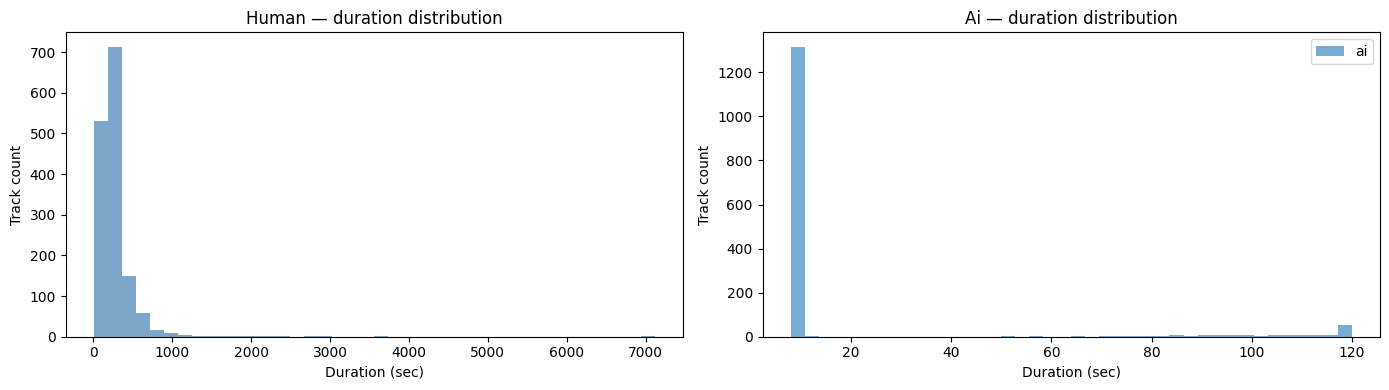


Saved → eda_duration_distribution.png


In [ ]:
meta_df = pd.read_csv(META_PATH)

# ── 1. Compute actual durations from files ────────────────────────────────
def get_duration(row):
    try:
        info = sf.info(row["file_path"])
        return info.duration
    except:
        return np.nan

print("Computing durations (fast — reads headers only, not audio)...")
meta_df["duration_sec"] = meta_df.apply(get_duration, axis=1)
meta_df.to_csv(META_PATH, index=False)  # update with real durations

# ── 2. Summary stats ──────────────────────────────────────────────────────
summary = meta_df.groupby("label")["duration_sec"].agg(
    count="count", mean="mean", median="median",
    min="min", max="max", total_min=lambda x: x.sum()/60
).round(2)
print("\nDuration stats by generator:")
print(summary.to_string())

# ── 3. Project chunk counts at different chunk sizes ─────────────────────
print("\n--- Projected chunk counts (no overlap) ---")
for chunk_sec in [10, 15, 30]:
    meta_df[f"chunks_{chunk_sec}s"] = (meta_df["duration_sec"] // chunk_sec).astype(int)
    proj = meta_df.groupby("label")[f"chunks_{chunk_sec}s"].sum()
    print(f"\nChunk size = {chunk_sec}s:")
    print(proj.to_string())
    print(f"  Human total : {proj[proj.index == 'human'].sum()}")
    print(f"  AI total    : {proj[proj.index != 'human'].sum()}")

# ── 4. Duration distributions ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, group in zip(axes, ["human", "ai"]):
    subset = meta_df[meta_df["label"] == group]
    if group == "ai":
        for gen, grp in subset.groupby("label"):
            ax.hist(grp["duration_sec"], bins=40, alpha=0.6, label=gen)
        ax.legend()
    else:
        ax.hist(subset["duration_sec"], bins=40, color="steelblue", alpha=0.7)
    ax.set_title(f"{group.capitalize()} — duration distribution")
    ax.set_xlabel("Duration (sec)")
    ax.set_ylabel("Track count")

plt.tight_layout()
plt.show()

In [ ]:
# How many AI tracks are actually long enough to yield at least one 20-sec chunk?
chunk_sec = 20
usable_ai = meta_df[(meta_df["label"] == "ai") & (meta_df["duration_sec"] >= chunk_sec)]
unusable_ai = meta_df[(meta_df["label"] == "ai") & (meta_df["duration_sec"] < chunk_sec)]

print(f"Usable AI tracks (>= {chunk_sec}s) : {len(usable_ai)}")
print(f"Unusable AI tracks (< {chunk_sec}s): {len(unusable_ai)}")
print(f"\nUsable AI chunks at 20s           : {int(usable_ai['duration_sec'].sum() // chunk_sec)}")
print(f"\nAI duration distribution (usable):")
print(usable_ai["duration_sec"].describe().round(2))

Usable AI tracks (>= 20s) : 182
Unusable AI tracks (< 20s): 1318

Usable AI chunks at 30s           : 909

AI duration distribution (usable):
count    182.00
mean      99.98
std       20.13
min       31.12
25%       87.00
50%      105.00
75%      119.95
max      120.00
Name: duration_sec, dtype: float64


In [19]:
CHUNK_SEC = 10

# ── Usable track analysis ─────────────────────────────────────────────────
meta_df["n_chunks"] = (meta_df["duration_sec"] // CHUNK_SEC).astype(int)
usable = meta_df[meta_df["n_chunks"] >= 1].copy()
unusable = meta_df[meta_df["n_chunks"] < 1].copy()

print(f"=== Usable tracks (>= {CHUNK_SEC}s) ===")
print(usable.groupby("label")["n_chunks"].agg(
    tracks="count", total_chunks="sum", avg_chunks="mean"
).round(2))

print(f"\n=== Unusable tracks (< {CHUNK_SEC}s) ===")
print(unusable.groupby("label").size())

# ── How many more AI tracks needed? ──────────────────────────────────────
human_chunks = usable[usable["label"] == "human"]["n_chunks"].sum()
ai_chunks    = usable[usable["label"] == "ai"]["n_chunks"].sum()
avg_chunks_per_ai = usable[usable["label"] == "ai"]["n_chunks"].mean()

extra_chunks_needed  = human_chunks - ai_chunks
extra_tracks_needed  = int(np.ceil(extra_chunks_needed / avg_chunks_per_ai))

print(f"\n=== Imbalance at {CHUNK_SEC}s chunks ===")
print(f"Human chunks      : {human_chunks:,}")
print(f"AI chunks (now)   : {ai_chunks:,}")
print(f"Gap               : {extra_chunks_needed:,} chunks")
print(f"Avg chunks/AI track: {avg_chunks_per_ai:.2f}")
print(f"Extra AI tracks needed: ~{extra_tracks_needed:,}")
print(f"\nAI shards already used : 74–{74 + 12} (Suno + MusicSet)")
print(f"Remaining AI shards    : {74 + 12}–146")
print(f"Remaining AI capacity  : ~{(146 - 74 - 12) * 136:,} tracks")

=== Usable tracks (>= 10s) ===
       tracks  total_chunks  avg_chunks
label                                  
ai       1439          3009        2.09
human    1496         41289       27.60

=== Unusable tracks (< 10s) ===
label
ai       61
human     4
dtype: int64

=== Imbalance at 10s chunks ===
Human chunks      : 41,289
AI chunks (now)   : 3,009
Gap               : 38,280 chunks
Avg chunks/AI track: 2.09
Extra AI tracks needed: ~18,307

AI shards already used : 74–86 (Suno + MusicSet)
Remaining AI shards    : 86–146
Remaining AI capacity  : ~8,160 tracks


Because AI-generated tracks are generally much shorter than human-produced ones, splitting the audio into fixed-length chunks will likely result in a highly imbalanced dataset. In addition, the current subset only includes music generated by two out of the three available AI generation sources. Therefore, downloading the remaining AI-generated tracks would help improve the balance of the dataset and provide broader coverage of different AI generation methods.


## Dowloading Remaining AI-generated Tracks

In [ ]:
# Shards 74–85 already downloaded → start from 86
REMAINING_AI_SHARDS = list(range(86, 147))   # 61 shards × 136 = ~8,296 tracks

print(f"Remaining AI shards : {len(REMAINING_AI_SHARDS)} (86–146)")
print(f"Expected tracks     : ~{len(REMAINING_AI_SHARDS) * 136:,}")
# ─────────────────────────────────────────────────────────────────────────

# ── Load existing metadata to get correct ID offset ──────────────────────
existing_meta = pd.read_csv(META_PATH)
existing_ai   = existing_meta[existing_meta["label"] == "ai"]
id_offset     = len(existing_ai)   # start numbering from where we left off
print(f"Existing AI tracks  : {id_offset} → new IDs start at {id_offset}")

meta_rows = []
meta_lock = threading.Lock()

def process_and_save(example, track_id):
    audio       = example["audio"]
    audio_array = audio["array"]
    sr          = audio["sampling_rate"]
    source      = example.get("source", "unknown")

    if audio_array.ndim > 1 and audio_array.shape[0] < audio_array.shape[1]:
        audio_array = audio_array.T
    if audio_array.ndim > 1:
        audio_array = audio_array.mean(axis=1)

    filename  = f"track_{track_id:05d}.wav"
    file_path = os.path.join(BASE_DIR, "ai", filename)
    sf.write(file_path, audio_array, sr, subtype='FLOAT')
    duration_sec = len(audio_array) / sr

    with meta_lock:
        meta_rows.append({
            "filename":     filename,
            "label":        "ai",
            "ai_generated": True,
            "generator":    "ai",
            "source":       source,
            "sample_rate":  sr,
            "duration_sec": round(duration_sec, 2),
            "n_samples":    len(audio_array),
            "file_path":    file_path,
        })

def download_remaining_ai():
    shard_urls = [f"{HF_BASE}/train-{i:05d}-of-00147.parquet"
                  for i in REMAINING_AI_SHARDS]

    ds = load_dataset("parquet",
                      data_files={"train": shard_urls},
                      split="train", streaming=True)
    ds = ds.cast_column("audio", Audio(sampling_rate=SAMPLE_RATE))

    count = 0
    for example in ds:
        process_and_save(example, id_offset + count)
        count += 1
        if count % 200 == 0:
            pct = count / (len(REMAINING_AI_SHARDS) * 136) * 100
            print(f"  [ai] {count:,} / ~{len(REMAINING_AI_SHARDS)*136:,}  ({pct:.1f}%)")

    print(f"  ✅ Done — {count:,} new AI tracks saved")
    return count

# ── Run ───────────────────────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"Downloading all remaining AI tracks...")
print(f"{'='*55}\n")

n_new = download_remaining_ai()

# ── Append to existing metadata ──────────────────────────────────────
new_meta_df  = pd.DataFrame(meta_rows)
updated_meta = pd.concat([existing_meta, new_meta_df], ignore_index=True)
updated_meta.to_csv(META_PATH, index=False)

# ── Summary ───────────────────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"New AI tracks downloaded : {n_new:,}")
print(f"Total rows in metadata   : {len(updated_meta):,}")
print(f"\nFull dataset breakdown:")
print(updated_meta.groupby(["label", "source"]).size().rename("tracks").to_string())

# ── Recompute chunk projections ───────────────────────────────────────────
CHUNK_SEC = 10
updated_meta["n_chunks"] = (updated_meta["duration_sec"] // CHUNK_SEC).astype(int)
usable = updated_meta[updated_meta["n_chunks"] >= 1]

print(f"\n=== Updated chunk counts at {CHUNK_SEC}s ===")
print(usable.groupby("label")["n_chunks"].agg(
    tracks="count", total_chunks="sum", avg_chunks_per_track="mean"
).round(2))

Remaining AI shards : 61 (86–146)
Expected tracks     : ~8,296
Existing AI tracks  : 1500 → new IDs start at 1500




Resolving data files:   0%|          | 0/61 [00:00<?, ?it/s]

  [ai] 200 / ~8,296  (2.4%)
  [ai] 400 / ~8,296  (4.8%)
  [ai] 600 / ~8,296  (7.2%)
  [ai] 800 / ~8,296  (9.6%)
  [ai] 1,000 / ~8,296  (12.1%)
  [ai] 1,200 / ~8,296  (14.5%)
  [ai] 1,400 / ~8,296  (16.9%)
  [ai] 1,600 / ~8,296  (19.3%)
  [ai] 1,800 / ~8,296  (21.7%)
  [ai] 2,000 / ~8,296  (24.1%)
  [ai] 2,200 / ~8,296  (26.5%)
  [ai] 2,400 / ~8,296  (28.9%)
  [ai] 2,600 / ~8,296  (31.3%)
  [ai] 2,800 / ~8,296  (33.8%)
  [ai] 3,000 / ~8,296  (36.2%)
  [ai] 3,200 / ~8,296  (38.6%)
  [ai] 3,400 / ~8,296  (41.0%)
  [ai] 3,600 / ~8,296  (43.4%)
  [ai] 3,800 / ~8,296  (45.8%)
  [ai] 4,000 / ~8,296  (48.2%)
  [ai] 4,200 / ~8,296  (50.6%)
  [ai] 4,400 / ~8,296  (53.0%)
  [ai] 4,600 / ~8,296  (55.4%)
  [ai] 4,800 / ~8,296  (57.9%)
  [ai] 5,000 / ~8,296  (60.3%)
  [ai] 5,200 / ~8,296  (62.7%)
  [ai] 5,400 / ~8,296  (65.1%)
  [ai] 5,600 / ~8,296  (67.5%)
  [ai] 5,800 / ~8,296  (69.9%)
  [ai] 6,000 / ~8,296  (72.3%)
  [ai] 6,200 / ~8,296  (74.7%)
  [ai] 6,400 / ~8,296  (77.1%)
  [ai] 6,600 / ~8,29

While variety of human generated music is much smaller than AI generated ones, our dataset from the perspective of 10 seconds chunks is closer to be balanced.